In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

In [4]:
df=pd.read_csv("../Data/raw/Data_Entry_2017_v2020.csv")

In [5]:
df.head()

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [6]:
df.columns

Index(['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID',
       'Patient Age', 'Patient Sex', 'View Position', 'OriginalImage[Width',
       'Height]', 'OriginalImagePixelSpacing[x', 'y]'],
      dtype='object')

In [7]:
df = df.rename(columns={
    "Image Index": "image_name",
    "Finding Labels": "finding_labels",
    "Follow-up #": "follow_up",
    "Patient ID": "patient_id",
    "Patient Age": "patient_age",
    "Patient Sex": "patient_sex",
    "View Position": "view_position",
    "OriginalImage[Width": "image_width",
    "Height]": "image_height",
    "OriginalImagePixelSpacing[x": "pixel_spacing_x",
    "y]": "pixel_spacing_y",
})


In [8]:
df.head()

,image_name,finding_labels,follow_up,patient_id,patient_age,patient_sex,view_position,image_width,image_height,pixel_spacing_x,pixel_spacing_y
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168


In [9]:
print(df["image_width"].describe())
print(df["image_height"].describe())

count    112120.000000
mean       2646.078844
std         341.246429
min        1143.000000
25%        2500.000000
50%        2518.000000
75%        2992.000000
max        3827.000000
Name: image_width, dtype: float64
count    112120.000000
mean       2486.438842
std         401.268227
min         966.000000
25%        2048.000000
50%        2544.000000
75%        2991.000000
max        4715.000000
Name: image_height, dtype: float64


In [10]:
df.isna().sum()

image_name         0
finding_labels     0
follow_up          0
patient_id         0
patient_age        0
patient_sex        0
view_position      0
image_width        0
image_height       0
pixel_spacing_x    0
pixel_spacing_y    0
dtype: int64

In [ ]:
df["label"] = (
    df["finding_labels"].str.strip().ne("No Finding")
).astype(int)

In [12]:
print("Number of Duplicated Rows :",df.duplicated().sum())
print("Number of Patients :",df["patient_id"].nunique())
print("Number of Images :",df["image_name"].nunique())


Number of Duplicated Rows : 0
Number of Patients : 30805
Number of Images : 112120


In [13]:
print(df["label"].value_counts(normalize=True).mul(100))
print(df["view_position"].value_counts(normalize=True).mul(100).round(2))

label
0    53.836068
1    46.163932
Name: proportion, dtype: float64
view_position
PA    60.03
AP    39.97
Name: proportion, dtype: float64


In [14]:
pd.crosstab(
    df["view_position"],
    df["label"],
    normalize="index"
).mul(100).round(2)

label,0,1
view_position,,
AP,47.00,53.00
PA,58.39,41.61


In [15]:
pd.crosstab(
    df["patient_sex"],
    df["label"],
    normalize="index"
).mul(100).round(2)

label,0,1
patient_sex,,
F,54.20,45.80
M,53.56,46.44


In [16]:
df["follow_up"].value_counts()

follow_up
0      30805
1      13302
2       9189
3       7089
4       5759
       ...  
179        1
180        1
181        1
182        1
183        1
Name: count, Length: 184, dtype: int64

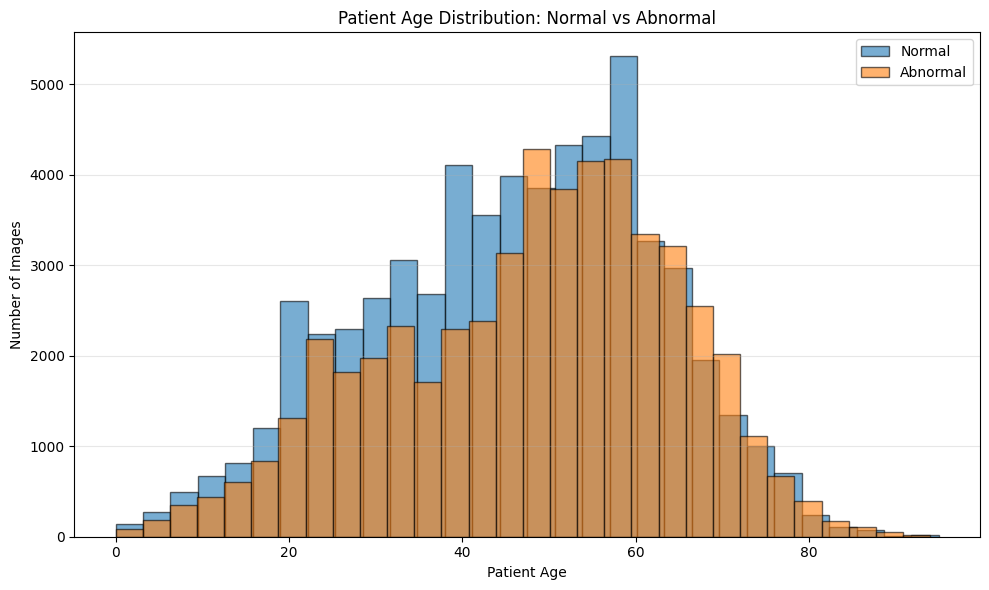

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.loc[df["label"] == 0, "patient_age"].dropna(),
    bins=30,
    alpha=0.6,
    label="Normal",
    edgecolor="black"
)

plt.hist(
    df.loc[df["label"] == 1, "patient_age"].dropna(),
    bins=30,
    alpha=0.6,
    label="Abnormal",
    edgecolor="black"
)

plt.xlabel("Patient Age")
plt.ylabel("Number of Images")
plt.title("Patient Age Distribution: Normal vs Abnormal")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
df.groupby("label")["patient_age"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,60361.0,45.48,16.53,0.0,33.0,47.0,58.0,95.0
1,51759.0,47.96,16.59,0.0,36.0,50.0,60.0,94.0


In [19]:
(df["patient_age"] == 0).sum()

np.int64(14)

In [20]:
df.loc[
    df["patient_age"] == 0,
    ["patient_id", "patient_age", "patient_sex",
     "view_position", "finding_labels", "label"]
]

,patient_id,patient_age,patient_sex,view_position,finding_labels,label
36231,9573,0,M,AP,No Finding,0
38783,10124,0,M,AP,No Finding,0
39077,10230,0,M,AP,No Finding,0
45965,11769,0,M,AP,No Finding,0
53031,13378,0,M,PA,Atelectasis,1
53114,13401,0,M,AP,Pleural_Thickening,1
57878,14333,0,M,AP,No Finding,0
66903,16529,0,F,AP,No Finding,0
73480,18069,0,M,AP,No Finding,0
77500,19045,0,F,AP,Infiltration,1


In [21]:
df[df["patient_age"]==0]["patient_id"]

36231     9573
38783    10124
39077    10230
45965    11769
53031    13378
53114    13401
57878    14333
66903    16529
73480    18069
77500    19045
79441    19515
81425    20008
85399    21044
95356    25066
Name: patient_id, dtype: int64

In [22]:
df[df["patient_age"]==0]["image_name"]

36231    00009573_000.png
38783    00010124_000.png
39077    00010230_000.png
45965    00011769_000.png
53031    00013378_000.png
53114    00013401_000.png
57878    00014333_000.png
66903    00016529_000.png
73480    00018069_001.png
77500    00019045_002.png
79441    00019515_000.png
81425    00020008_002.png
85399    00021044_000.png
95356    00025066_000.png
Name: image_name, dtype: object

In [23]:
df["follow_up"].describe()

count    112120.000000
mean          8.573751
std          15.406320
min           0.000000
25%           0.000000
50%           3.000000
75%          10.000000
max         183.000000
Name: follow_up, dtype: float64

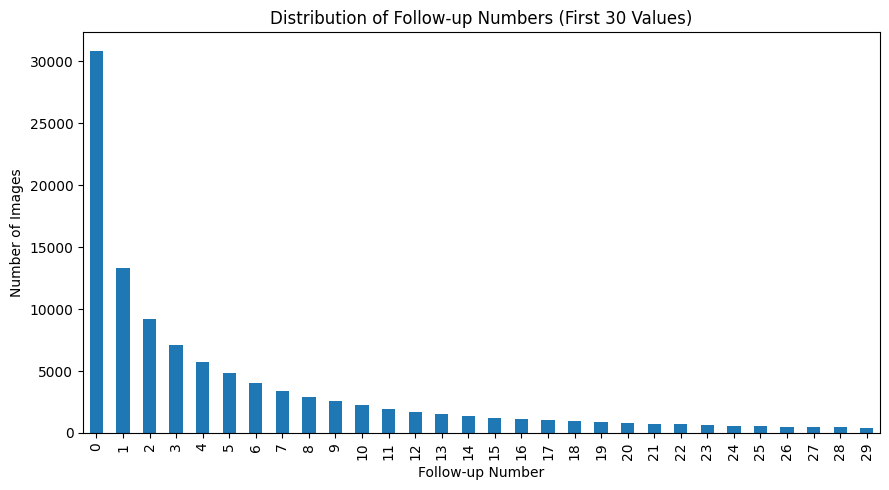

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

df["follow_up"].value_counts().sort_index().head(30).plot(kind="bar")

plt.xlabel("Follow-up Number")
plt.ylabel("Number of Images")
plt.title("Distribution of Follow-up Numbers (First 30 Values)")
plt.tight_layout()
plt.show()

In [25]:
df["patient_id"].value_counts().describe()

count    30805.000000
mean         3.639669
std          7.266734
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
Name: count, dtype: float64

In [26]:
(df["patient_id"].value_counts() > 1).sum()

np.int64(13302)

In [27]:
from collections import Counter

disease_counts = Counter()

for labels in df["finding_labels"].dropna():
    for disease in labels.split("|"):
        disease_counts[disease] += 1

disease_counts = pd.Series(disease_counts).sort_values(ascending=False)

disease_counts

No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
dtype: int64

In [28]:
disease_percentages = (
    disease_counts / len(df) * 100
).round(2)

disease_percentages

No Finding            53.84
Infiltration          17.74
Effusion              11.88
Atelectasis           10.31
Nodule                 5.65
Mass                   5.16
Pneumothorax           4.73
Consolidation          4.16
Pleural_Thickening     3.02
Cardiomegaly           2.48
Emphysema              2.24
Edema                  2.05
Fibrosis               1.50
Pneumonia              1.28
Hernia                 0.20
dtype: float64